# HW6 Lab: Sentence Embeddings and Semantic Search 🔎

<!-- lab-header:begin -->
**MIS 769 · Big Data Analytics for Business · Fall 2026**

**Points:** 40  |  **Due:** Sunday, October 11, 2026 at 10:00 PM Pacific

**Dr. Richard J. Young** · UNLV Lee Business School
<!-- lab-header:end -->

> **Why are we learning this?** Word2Vec gave every *word* a vector; sentence
> transformers give every *sentence or document* one — so "films I didn't enjoy" can
> match "this movie was a waste of time" even though they share zero keywords. This is
> the engine inside modern search, dedup, FAQ bots, and the "R" in RAG (coming in a later
> lab). The transferable skill: **finding things by meaning instead of by matching
> strings** — the single biggest upgrade you can make to any internal search box.

**How this lab works:** every cell below runs as-is — Runtime → Run all builds a working
semantic search engine over 2,000 movie reviews. Your job: understand it, twist the
knobs in the 🧪 Experiment cells, then build semantic search over documents from **a
domain you're passionate about** in the 🎮 Playground.

**The pipeline:** Load SBERT → encode text → measure similarity → build a search function → beat keyword search


## Learning objectives

- Explain the difference between word embeddings (HW4) and sentence embeddings
- Encode sentences and a 2,000-document corpus with a Sentence Transformer
- Compute and visualize cosine similarity between texts
- Build a `semantic_search()` function and show where it beats keyword search


## Part 1: Setup and Model Loading (6 pts)

We use **`sentence-transformers/all-MiniLM-L6-v2`** — the workhorse SBERT model: 384
dimensions, fast on CPU, good enough that companies actually ship it.

> 💡 A stronger modern alternative is `BAAI/bge-small-en-v1.5` — same code, swap the
> model name if you want to compare.


In [13]:
!pip install -q sentence-transformers datasets pandas scikit-learn matplotlib seaborn

from sentence_transformers import SentenceTransformer
import numpy as np, pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import seaborn as sns

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

print("📊 MODEL LOADED")
print(f"   Embedding dimension: {model.get_sentence_embedding_dimension()}")
print(f"   Max sequence length: {model.max_seq_length} tokens")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

📊 MODEL LOADED
   Embedding dimension: 384
   Max sequence length: 256 tokens


/tmp/ipykernel_563/3038990048.py:12: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(f"   Embedding dimension: {model.get_sentence_embedding_dimension()}")


### Load the corpus

**2,000 IMDB movie reviews** — long, opinionated, vocabulary-rich text, ideal for showing
semantic matches that keyword search misses. Bounded so encoding takes ~1-2 minutes on
free Colab CPU.


In [14]:
from datasets import load_dataset

dataset = load_dataset("stanfordnlp/imdb", split="train[:2000]")
df = dataset.to_pandas()
print(f"✅ Loaded {len(df):,} reviews")
print("Columns:", list(df.columns))
print("\nSample:", df["text"].iloc[0][:200], "...")

✅ Loaded 2,000 reviews
Columns: ['text', 'label']

Sample: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ev ...


## Part 2: Text Encoding (8 pts)

`model.encode()` turns any text into a fixed-length vector where **direction encodes
meaning**. First on five hand-picked sentences (watch sentences 1-2: same meaning,
different words — and 4-5: same word "bank", different meanings), then on the whole
corpus in one batched call.


In [15]:
sentences = [
    "This movie was absolutely fantastic!",
    "I loved this film, it was great!",
    "The movie was terrible and boring.",
    "The bank is by the river.",
    "I need to visit the bank for a loan.",
]

embeddings = model.encode(sentences)
print("📊 SENTENCE EMBEDDINGS")
print(f"   {len(sentences)} sentences → matrix of shape {embeddings.shape}")
print(f"   First embedding, first 10 values:\n   {embeddings[0][:10].round(3)}")

📊 SENTENCE EMBEDDINGS
   5 sentences → matrix of shape (5, 384)
   First embedding, first 10 values:
   [-0.092  0.036 -0.073  0.054 -0.026  0.012 -0.053 -0.024 -0.009 -0.048]


In [16]:
# Encode the whole corpus (batched — one call, with a progress bar)
texts = [t[:512] for t in df["text"].tolist()]   # truncate: speed + memory
print("Encoding 2,000 reviews (~1-2 minutes on CPU)...")
corpus_embeddings = model.encode(texts, show_progress_bar=True)
print(f"\n✅ Corpus embeddings shape: {corpus_embeddings.shape}")

Encoding 2,000 reviews (~1-2 minutes on CPU)...


Batches:   0%|          | 0/63 [00:00<?, ?it/s]


✅ Corpus embeddings shape: (2000, 384)


### 🧪 Experiment

- Add a sarcastic sentence to `sentences` — "Oh great, another masterpiece of boredom." — and re-run Parts 2-3. Does the model file it with the raves or the pans? (Sarcasm is embedding kryptonite.)
- Add the same sentence twice, once ALL-CAPS with exclamation points. How close are the two vectors — does the model care about shouting?
- Every input becomes exactly 384 numbers — check `model.encode(["hi"]).shape` vs a whole paragraph. What must get thrown away for a long review, and where would that hurt?


In [17]:
# part 2 experiment 1
sentences = [
    "This movie was absolutely fantastic!",
    "I loved this film, it was great!",
    "The movie was terrible and boring.",
    "The bank is by the river.",
    "I need to visit the bank for a loan.",
    "Oh great, another masterpiece of boredom."
]

embeddings = model.encode(sentences)
print("📊 SENTENCE EMBEDDINGS")
print(f"   {len(sentences)} sentences → matrix of shape {embeddings.shape}")
print(f"   First embedding, first 10 values:\n   {embeddings[0][:10].round(3)}")

# Encode the whole corpus (batched — one call, with a progress bar)
texts = [t[:512] for t in df["text"].tolist()]   # truncate: speed + memory
print("Encoding 2,000 reviews (~1-2 minutes on CPU)...")
corpus_embeddings = model.encode(texts, show_progress_bar=True)
print(f"\n✅ Corpus embeddings shape: {corpus_embeddings.shape}")

📊 SENTENCE EMBEDDINGS
   6 sentences → matrix of shape (6, 384)
   First embedding, first 10 values:
   [-0.092  0.036 -0.073  0.054 -0.026  0.012 -0.053 -0.024 -0.009 -0.048]
Encoding 2,000 reviews (~1-2 minutes on CPU)...


Batches:   0%|          | 0/63 [00:00<?, ?it/s]


✅ Corpus embeddings shape: (2000, 384)


In [18]:
# part 2 experiment 2
sentences = [
    "This movie was absolutely fantastic!",
    "I loved this film, it was great!",
    "The movie was terrible and boring.",
    "The bank is by the river.",
    "I need to visit the bank for a loan.",
    "Oh great, another masterpiece of boredom.",
    "OH GREAT, ANOTHER MASTERPIECE OF BOREDOM!!"
]

embeddings = model.encode(sentences)
print("📊 SENTENCE EMBEDDINGS")
print(f"   {len(sentences)} sentences → matrix of shape {embeddings.shape}")
print(f"   First embedding, first 10 values:\n   {embeddings[0][:10].round(3)}")

# Encode the whole corpus (batched — one call, with a progress bar)
texts = [t[:512] for t in df["text"].tolist()]   # truncate: speed + memory
print("Encoding 2,000 reviews (~1-2 minutes on CPU)...")
corpus_embeddings = model.encode(texts, show_progress_bar=True)
print(f"\n✅ Corpus embeddings shape: {corpus_embeddings.shape}")

📊 SENTENCE EMBEDDINGS
   7 sentences → matrix of shape (7, 384)
   First embedding, first 10 values:
   [-0.092  0.036 -0.073  0.054 -0.026  0.012 -0.053 -0.024 -0.009 -0.048]
Encoding 2,000 reviews (~1-2 minutes on CPU)...


Batches:   0%|          | 0/63 [00:00<?, ?it/s]


✅ Corpus embeddings shape: (2000, 384)


In [19]:
# part 2 experiment 3

# 1. Shape check: tiny input vs. a full paragraph vs. the longest review in the corpus
short_emb = model.encode(["hi"])
paragraph = ("I went into this this japanense stationary shop searching, really hunting for model die cast cars of my favorite japanense sport cars.")
para_emb = model.encode([paragraph])
longest_review = df["text"].iloc[df["text"].str.len().argmax()]
long_emb = model.encode([longest_review])

print("📏 SHAPES")
print(f"   'hi'            → {short_emb.shape}")
print(f"   japanese       → {para_emb.shape}")
print(f"   longest review  → {long_emb.shape}")

# 2. How much of the long review does the model actually see?
tok = model.tokenizer
total_tokens = len(tok(longest_review)["input_ids"])
limit = model.max_seq_length
print(f"\n✂️  TRUNCATION")
print(f"   Review length: {len(longest_review):,} characters, {total_tokens} tokens")
print(f"   Model limit:   {limit} tokens")
print(f"   Tokens discarded: {max(total_tokens - limit, 0)}")

kept_ids = tok(longest_review, truncation=True, max_length=limit)["input_ids"]
kept_text = tok.decode(kept_ids, skip_special_tokens=True)
print(f"\n   LAST 150 chars the model SAW:\n   ...{kept_text[-150:]}")
print(f"\n   LAST 150 chars the model NEVER SAW:\n   ...{longest_review[-150:]}")

# 3. Proof: changing the tail of a long review doesn't change its vector
twisted = longest_review + " BUT THE ENDING WAS AWFUL AND I HATED EVERY MINUTE OF IT."
twisted_emb = model.encode([twisted])
sim = cosine_similarity(long_emb, twisted_emb)[0][0]
print(f"\n🔬 Similarity between original and 'twisted ending' version: {sim:.4f}")

📏 SHAPES
   'hi'            → (1, 384)
   japanese       → (1, 384)
   longest review  → (1, 384)


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1683 > 256). Running this sequence through the model will result in indexing errors



✂️  TRUNCATION
   Review length: 7,382 characters, 1683 tokens
   Model limit:   256 tokens
   Tokens discarded: 1427

   LAST 150 chars the model SAW:
   ... disrupts his plans when his best - friend harold ( kevin rivera ) comes - a - looking for him. caught in the attempt by harold and his sister, victor

   LAST 150 chars the model NEVER SAW:
   ...on't like him, so ultimately how can I like a film about him? So if you'll excuse me, I'm going to go stick my hands into a bowl of grits.<br /><br />

🔬 Similarity between original and 'twisted ending' version: 1.0000


## Part 3: Similarity Computation (10 pts)

**Cosine similarity** measures the angle between two vectors: ~1.0 = same meaning,
~0.0 = unrelated. This one number is the entire foundation of semantic search — so watch
it computed explicitly before any library hides it from you. Three diagnostic pairs
(same sentiment / opposite sentiment / two meanings of "bank"), then the full 5×5 matrix
as a heatmap:


🔍 SEMANTIC SIMILARITY

   A: "This movie was absolutely fantastic!"
   B: "I loved this film, it was great!"
   similarity = 0.82

   A: "This movie was absolutely fantastic!"
   B: "The movie was terrible and boring."
   similarity = 0.42

   A: "The bank is by the river."
   B: "I need to visit the bank for a loan."
   similarity = 0.54


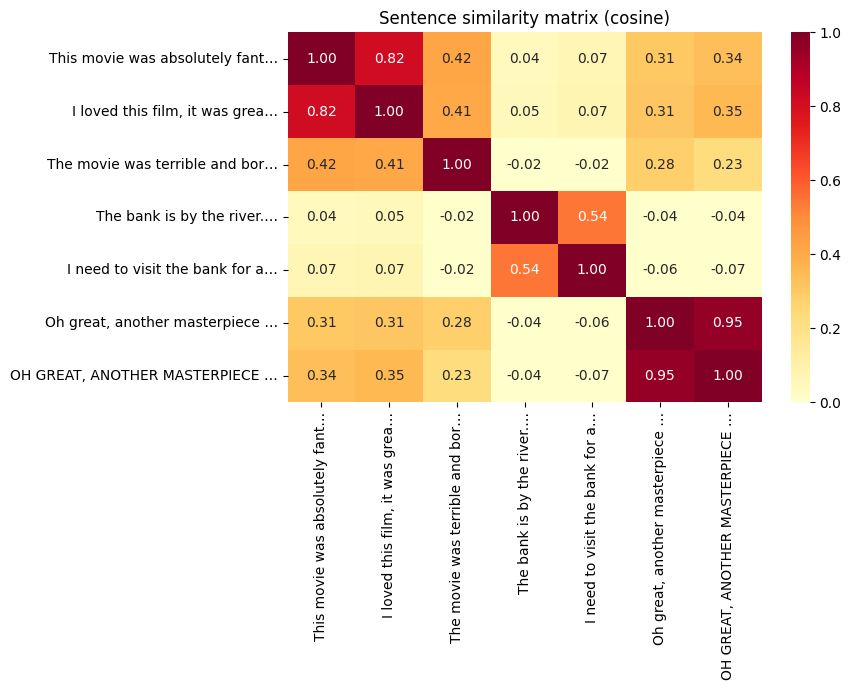

In [20]:
print("🔍 SEMANTIC SIMILARITY")
for i, j in [(0, 1), (0, 2), (3, 4)]:
    sim = cosine_similarity([embeddings[i]], [embeddings[j]])[0][0]
    print(f'\n   A: "{sentences[i]}"')
    print(f'   B: "{sentences[j]}"')
    print(f"   similarity = {sim:.2f}")

similarity_matrix = cosine_similarity(embeddings)
plt.figure(figsize=(9, 7))
sns.heatmap(similarity_matrix,
            xticklabels=[s[:30] + "…" for s in sentences],
            yticklabels=[s[:30] + "…" for s in sentences],
            annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1)
plt.title("Sentence similarity matrix (cosine)")
plt.tight_layout()
plt.show()

### 🧪 Experiment

- Write your own trap pair: two sentences that share NO words but mean the same thing ("The flick blew my mind" / "An astonishing piece of cinema"). What score do they get?
- Now the reverse trap: same words, opposite meanings ("The dog bit the mailman" / "The mailman bit the dog"). Does the model notice who bit whom?
- Swap the model for `BAAI/bge-small-en-v1.5` (reload in Part 1, re-run 2-3). Do your trap pairs score better — is the upgrade worth it?


**Pause and look (feeds Q1):** the two positive reviews should score far higher with
each other than with the negative one — despite sharing almost no words. And the two
"bank" sentences should score LOW: the model read the *context*, not the string. That's
the entire pitch of this technology in one heatmap.


## Part 4: Semantic Search (10 pts)

Time to productize: a function that takes any query and returns the k most similar
documents. This exact pattern — encode query, compare to pre-encoded corpus, sort, return
top-k — is what powers FAQ bots, support-ticket routing, and RAG retrieval. Four steps,
each one visible:


In [21]:
def semantic_search(query, corpus_embeddings, corpus_texts, top_k=5):
    """Return the top_k most semantically similar documents to `query`."""
    query_embedding = model.encode([query])                                   # 1. encode query
    similarities = cosine_similarity(query_embedding, corpus_embeddings)[0]   # 2. score every doc
    top_indices = np.argsort(similarities)[::-1][:top_k]                      # 3. best first
    return [{"score": similarities[idx], "text": corpus_texts[idx][:200] + "…"}
            for idx in top_indices]                                           # 4. package results

query = "movies with surprising plot twists"
print(f'🔎 Query: "{query}"\n')
for i, r in enumerate(semantic_search(query, corpus_embeddings, texts), 1):
    print(f"{i}. [score {r['score']:.2f}] {r['text']}\n")

🔎 Query: "movies with surprising plot twists"

1. [score 0.55] TV version of "Twister" springs a few leaks but manages to remain watchable. My sister bought this at a Wal-Mart a few years back when it was released, I saw it back then and thought it was okay. Late…

2. [score 0.55] Look carefully at the wonderful assortment of talent put together to make this movie: Connery, Fishburne, Capshaw, Harris, Underwood, Beatty, Thigpen, even cameos by Slezak, Lange, and Plimpton. They …

3. [score 0.55] I can't believe the likes of Guillermo del Toro and Kim Bassinger got involved ins this piece of garbage! The script is so poorly written and the directing so weak (both by the same person) that its h…

4. [score 0.54] Weak plot, predictable violence, only semi interesting characters. Like the writer (also one of the stars?) was fictionalizing his own screw ups and added an incredulous fantasies of drugs and murder …

5. [score 0.52] The genre of suspense films really takes a dive in this one. 

In [22]:
# Stress-test with more queries — vary tone, topic, and phrasing
for query in ["heartwarming family movies",
              "scary horror films",
              "romantic comedy with happy ending"]:
    print("=" * 60)
    print(f'Query: "{query}"')
    for i, r in enumerate(semantic_search(query, corpus_embeddings, texts, top_k=3), 1):
        print(f"  {i}. [{r['score']:.2f}] {r['text'][:100]}…")
    print()

Query: "heartwarming family movies"
  1. [0.49] I very much looked forward to this movie. Its a good family movie; however, if Michael Landon Jr.'s …
  2. [0.48] "Valentine" is another horror movie to add to the stalk and slash movie list (think "Halloween", "Fr…
  3. [0.48] Jack Frost, no kids it's not the warm hearted family movie about a dad who comes back from the dead …

Query: "scary horror films"
  1. [0.65] This is the single worst movie I have ever seen. Let me say that again: THIS IS THE SINGLE WORST MOV…
  2. [0.64] normally i'm not the sort to be scared by horror movies, but this movie is the exception. some how t…
  3. [0.62] A far as B-movies go, SCARECROW is one of those that are so bad, that it becomes incredibly annoying…

Query: "romantic comedy with happy ending"
  1. [0.55] A poorly written script with no likeable characters. As for it being a comedy, I forgot to laugh. It…
  2. [0.55] be warned: this movie tells lots of love stories without any coherence.<br /><br 

### 🧪 Experiment

- Swap the query in `semantic_search` for slang — "flicks that are straight fire" or "movies that slap" — does SBERT keep up with how people actually talk?
- Query with typos: "horor movei with gost". Keyword search dies instantly on typos — does semantic search survive them?
- Print the WORST matches too: `np.argsort(similarities)[:3]` inside a copy of the function. What does the model consider maximally unrelated to "scary horror films" — and do you agree?


**Pause and look (feeds Q3):** at least one result above is probably wrong in an
interesting way (a horror review matching "heartwarming" because it mentions family,
say). Find your best failure and diagnose it — the model matches *overall meaning*, and
reviews mix praise, plot, and complaints in one blob.


## Part 5: Analysis (6 pts)

The showdown: your semantic search vs. plain keyword matching, on a query where the
words and the meaning point in different directions. Note the irony in the keyword
column — a substring match for "enjoy" happily returns reviews saying "really enjoyed!"


In [23]:
query = "films I didn't enjoy"
print(f'📊 SEMANTIC vs KEYWORD — query: "{query}"\n')

print("SEMANTIC SEARCH (embedding-based):")
for i, r in enumerate(semantic_search(query, corpus_embeddings, texts, top_k=3), 1):
    print(f"  {i}. [{r['score']:.2f}] {r['text'][:80]}…")

print("\nKEYWORD SEARCH (substring match on 'enjoy'):")
keyword_hits = [t for t in texts if "enjoy" in t.lower()][:3]
if keyword_hits:
    for i, t in enumerate(keyword_hits, 1):
        print(f"  {i}. {t[:80]}…")
else:
    print("  No exact matches found!")

print("\n💡 Keyword search matches the WORD (including 'really enjoyed!');")
print("   semantic search matches the MEANING (negative experiences).")

📊 SEMANTIC vs KEYWORD — query: "films I didn't enjoy"

SEMANTIC SEARCH (embedding-based):
  1. [0.58] There are bad movies, terrible movies even boring movies...I can watch most and …
  2. [0.57] There are bad movies, then there are the movies that are SO bad, that they becom…
  3. [0.55] Personally, while I'm able to appreciate really good movies, I also have a stran…

KEYWORD SEARCH (substring match on 'enjoy'):
  1. Really, I can't believe that I spent $5 on this movie. I am a huge zombie fanati…
  2. I very much looked forward to this movie. Its a good family movie; however, if M…
  3. I have read all of the Love Come Softly books. Knowing full well that movies can…

💡 Keyword search matches the WORD (including 'really enjoyed!');
   semantic search matches the MEANING (negative experiences).


### 🧪 Experiment

- Run the same showdown for "movies that put me to sleep" (keyword: 'sleep'). Which keyword hits are about literal sleeping — and which semantic hits understood the insult?
- Find a query where KEYWORD wins: search for an exact movie title or actor name both ways. Why do exact identifiers favor strings over meaning — and what does that imply for invoice numbers and SKUs at work?
- Score the two result sets yourself: for each of the 3+3 results above, mark relevant/irrelevant by hand. What's your mini precision score for each engine?


## 🎮 Your Domain Playground

Build semantic search over documents from **your** world — and be the judge of the
results. Game patch notes, song lyrics from your genre, sneaker release blurbs, F1 race
reports, fanfic summaries, your company's FAQ or support tickets, job postings in your
field. A few hundred documents is plenty; you know what a *good* search result looks
like in that world, which makes you the perfect evaluator.

# 1. **Load your documents.** Pick ONE loader and adapt:


In [25]:
# loading in data

from datasets import load_dataset

ds = load_dataset("hugginglearners/amazon-reviews-sentiment-analysis")
print(ds)

my_df = ds["train"].select(range(2000)).to_pandas()   # first 2,000 rows
print("Columns:", list(my_df.columns))
print(my_df.head(3))

DatasetDict({
    train: Dataset({
        features: ['Unnamed: 0', 'reviewerName', 'overall', 'reviewText', 'reviewTime', 'day_diff', 'helpful_yes', 'helpful_no', 'total_vote', 'score_pos_neg_diff', 'score_average_rating', 'wilson_lower_bound'],
        num_rows: 4915
    })
})
Columns: ['Unnamed: 0', 'reviewerName', 'overall', 'reviewText', 'reviewTime', 'day_diff', 'helpful_yes', 'helpful_no', 'total_vote', 'score_pos_neg_diff', 'score_average_rating', 'wilson_lower_bound']
   Unnamed: 0 reviewerName  overall  \
0           0         None      4.0   
1           1         0mie      5.0   
2           2          1K3      4.0   

                                          reviewText  reviewTime  day_diff  \
0                                         No issues.  2014-07-23       138   
1  Purchased this for my device, it worked as adv...  2013-10-25       409   
2  it works as expected. I should have sprung for...  2012-12-23       715   

   helpful_yes  helpful_no  total_vote  score_po

In [27]:
# setting text columns, purge nulls and junk, set embeddings
my_text_column = "reviewText"

my_df = my_df.dropna(subset=[my_text_column])

my_texts = [str(t)[:512] for t in my_df[my_text_column]]
my_embeddings = model.encode(my_texts, show_progress_bar=True)
print(f"✅ {len(my_texts):,} docs → embeddings {my_embeddings.shape}")

Batches:   0%|          | 0/63 [00:00<?, ?it/s]

✅ 1,986 docs → embeddings (1986, 384)


# 2. Encode corpus with 5 searches

In [28]:
# queries
queries = [
    "stopped working after a few weeks",
    "very slow transfer speed",
    "lost my files or data got corrupted",
    "works perfectly in my phone",
    "great value for the money",
]

# for loop to print the closest matching 3 reviews
for query in queries:
    print("=" * 60)
    print(f'Query: "{query}"')
    for i, r in enumerate(semantic_search(query, my_embeddings, my_texts, top_k=3), 1):
        print(f"  {i}. [{r['score']:.2f}] {r['text'][:100]}…")

Query: "stopped working after a few weeks"
  1. [0.47] A month and a half after purchase...  My device powered off while the card was in use (batteries ran…
  2. [0.45] after 3 months would not read at all. Used all sorts of card readers and computers and internals wen…
  3. [0.45] I started to have trouble with my card after about 3 months. I shall attempt to get a replacement an…
Query: "very slow transfer speed"
  1. [0.72] super fast transfer speed. very very impressed with the price as well. I'll be getting another no do…
  2. [0.68] Very fast transfer speeds and it feels like it is very good build quality. Great price too and would…
  3. [0.67] Great transfer speeds for my Tablet. Going on a month now and it works just fine. Highly recommend i…
Query: "lost my files or data got corrupted"
  1. [0.47] after 3 months would not read at all. Used all sorts of card readers and computers and internals wen…
  2. [0.47] i still own it but card went bad after 2 weeks of owning it, lost to

# 3. Re-Run of Part 5 Showdown

In [29]:
# Playground: semantic vs keyword showdown on my corpus
query = "it died on me"
keyword = "died"

print(f'📊 SEMANTIC vs KEYWORD — query: "{query}"\n')

# run the embeddings search and print top 3 matches
print("SEMANTIC SEARCH (embedding-based):")
for i, r in enumerate(semantic_search(query, my_embeddings, my_texts, top_k=3), 1):
    print(f"  {i}. [{r['score']:.2f}] {r['text'][:80]}…")

# scan to match on exact string
print(f"\nKEYWORD SEARCH (substring match on '{keyword}'):")
keyword_hits = [t for t in my_texts if keyword in t.lower()]
print(f"  ({len(keyword_hits)} total reviews contain '{keyword}')")

# show first 3 matches or none if there arent any
if keyword_hits:
    for i, t in enumerate(keyword_hits[:3], 1):
        print(f"  {i}. {t[:80]}…")
else:
    print("  No exact matches found!")

print("\n💡 Keyword search only finds reviews that use the exact word;")
print("   semantic search matches the MEANING (the card failing).")

📊 SEMANTIC vs KEYWORD — query: "it died on me"

SEMANTIC SEARCH (embedding-based):
  1. [0.43] Piece of crap died two months after I bought itI am sure that makes it on me to …
  2. [0.34] I bought one but it died on my galaxy s4 but i sent it in to sand disk and they …
  3. [0.30] It was good until I lost it in the house.  I think they should put a big ass lig…

KEYWORD SEARCH (substring match on 'died'):
  (17 total reviews contain 'died')
  1. I bought 2 of those SanDisk 32 GB microSD , used them on my Galaxy Note and Gala…
  2. I used this for a few months in my phone, then it decided to quit mounting. I lo…
  3. I am very disappointed in this card.  I usually don't have an issue with SanDisk…

💡 Keyword search only finds reviews that use the exact word;
   semantic search matches the MEANING (the card failing).


Output shows 17 matches for the string match but no keyword matched inside of the preview. Doing a regex to confirm why it shows as a match

In [30]:
import re
for t in keyword_hits[:5]:
    m = re.search("died", t.lower())
    s = max(m.start() - 40, 0)
    print(f"...{t[s:m.end() + 40]}...\n")

...moved , then recognize it again :) then diedI thought it's just a luck , plugged in ...

...nting. I lost some pictures of pets who died shortly after. I got a replacement card...

... with SanDisk, but this 32GB ultra card died after two months.  Died as in, no longe...

... have no problems with it and it hasn't died on my yet.It's been about 4 months at l...

...What can i say my old 8GB died and this is working like a champ trust ...



# 4. Insider Test Analysis

## Insider test

The best query from the set was **"stopped working after a few weeks"**. There were salso ome successful meaning searches  the searched returned results without matching on the search phrase "stopped working". Those queries were **"after 3 months would not read at all,", "powered off while the card was in use,", and "trouble with my card after about 3 months,"**. Since none of these results have the searched phrase ctrl-f would have failed to find them.

Not everything was a success though. The worst failure was **"very slow transfer speed"** returned three reviews praising *fast* transfer speeds at the highest scores of any query (0.67-0.72). This is a failure because the model matched the topic and ignored the direction of the sentiment. This is a Part 3 problem likely due to blending and not neccessarily a truncation issue or corpus. It is likely not truncation because the return searches are not cutoff and don't hit the character limit. The reviews are short and the meaning of the review is understood almost in the first few words. The vertoring values are also very close together so the model could see each review as very similar.

Compared to the IMBD demo the IMBD search appeared to be more reliable likely due to the IMBD reviews being more varied in sentiment, longer, and likely exceed the character cutoff so vectoring gets murkier than my data set which has shorter reviews, no cahracter exceeding opportunities, single focus on one product so langauge variation is going to be more limited, and finally no vertor murkiness.

# HW Answers

Q1: What makes two sentences similar according to the model?

A1. The model converts each sentence into a vector of numbers, 384 in the case of this model, that captures its meaning and context, not its exact words. Two sentences are similar when their vectors point in nearly the same direction, which is measured by cosine similarity. This means sentences with different wording but the same meaning score very high due to matching semantics.
<br>

Q2: Find an example where semantic search works better than keyword search.

A2. On my micro sd query, the query **"stopped working after a few weeks"** returned three reviews that did not have the matching search query. So in an extact phrase match these results would have been missed or even searching with ctrl-f.
<br>

Q3: Find an example where the model fails and explain why?

A3. The model failed for the query **"very slow transfer speed**. Semantically you would expect the review to be negative and talking about a slow transfer speed/performance. Instead the return results were about fast transfer speeds and praising the performance. The model failed here because it matched on transfer speed and ignored the direction of slow vs fast. The model had a failure due to embedding compression. The reviews are not using multiple adjectives so subject matter and structure are outweighing the single use of an adjective. It would be interesting to find reviews that used multiple negative adjectives to see if this compression embedding issue holds true though...
<br>


Q4: How would you use this in a business application?

A4. I would use this model to search through customer survey reposnes of a product or user experience. My current work is as an Aanlytics Engineer for the UXUI team. So, adapting this model to look at reviews by design feature to find friction points would be the likley applicaiton. Especially if the design feature are revenue generating such as paing your bill, a fee collection for a service or something. Showing the survey analysis prior to the design changes that reduce friction and comparing after would be how I present if the experiment is successful. Also bonus value if I could track or compare that prior friction to an uptick in customer support calls and show call demand dropping.

2. **Encode your corpus and run at least 5 searches** that only an insider would think
   to make — jargon queries, slang queries, "vibe" queries ("songs for a late-night
   drive", "patches that nerfed my main", "tickets where the customer is about to churn").
3. **Re-run the Part 5 showdown** on your corpus: one query where semantic search should
   beat keyword search, with the keyword column for contrast.
4. **The insider test (markdown cell, 4–6 sentences):** as a domain insider, grade the
   results. Which query did semantic search nail that Ctrl-F never could? Where did it
   embarrass itself — and is the failure a Part 3 problem (meaning blended away), a
   truncation problem (512 chars), or a corpus problem? Compare against the IMDB demo:
   which corpus was semantic search *better* at, and why do you think that is?

## 🤔 Debrief

1. You propose replacing your company's intranet keyword search with this. What breaks
   at 10 million documents (hint: today you compared the query against EVERY document —
   the fix, vector indexes like FAISS, arrives in the RAG lab)? And what about exact-match
   queries like invoice numbers or SKUs?
2. The model compressed each review to 384 numbers built from its first 512 tokens.
   What information got thrown away, and for which business search tasks would that loss
   be unacceptable?


## 📤 Submit (HW6 — 40 points)

**Deliverables (submit through Canvas):**
- Completed `.ipynb` executed top-to-bottom, INCLUDING the Playground semantic search over your own domain's documents (heatmap and both search runs visible)

**Answer these questions in a markdown cell at the end of your notebook:**
- **Q1:** What makes two sentences similar according to the model?
- **Q2:** Find an example where semantic search works better than keyword search
- **Q3:** Find an example where the model fails and explain why
- **Q4:** How would you use this in a business application?

**Grading:**

| Part | Points |
|---|---|
| Part 1: Setup and Model Loading | 6 |
| Part 2: Text Encoding | 8 |
| Part 3: Similarity Computation | 10 |
| Part 4: Semantic Search | 10 |
| Part 5: Analysis | 6 |

**Due Sunday 10:00 p.m.** — see the Canvas assignment for the exact date. Late work is not accepted (see syllabus).

*AI policy: AI tools are allowed and encouraged. Add one line acknowledging what you used, and be ready to explain every part of what you submit.*
